# LangGraph calling APIs


In [1]:
import random

import requests
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain.messages import (
    HumanMessage,
    SystemMessage,
)
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode

In [2]:
load_dotenv()

model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_tokens=500,
    timeout=50,
    reasoning_effort="low",
    max_retries=2,
)

In [3]:
@tool
def get_random_post_tool():
    """
    Fetches a random post from the JSONPlaceholder API and returns it.
    """
    post_id = random.randint(1, 10)

    url = f"https://jsonplaceholder.typicode.com/posts/{post_id}"

    try:
        response = requests.get(url)

        if response.status_code == 200:
            post = response.json()
            return post
        else:
            print("Error:", response.status_code)
            return None
    except requests.exceptions.RequestException as e:
        print("Error:", e)
        return None

In [4]:
get_random_post_tool.invoke({})

{'userId': 1,
 'id': 10,
 'title': 'optio molestias id quia eum',
 'body': 'quo et expedita modi cum officia vel magni\ndoloribus qui repudiandae\nvero nisi sit\nquos veniam quod sed accusamus veritatis error'}

In [5]:
tools = [get_random_post_tool]

In [6]:
llm_with_tools = llm.bind_tools(tools)

In [7]:
def agent(state: MessagesState):
    ai_message = llm_with_tools.invoke(state["messages"])
    return {"messages": ai_message}

In [8]:
def router(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"

    return END

In [9]:
workflow = StateGraph(MessagesState)

workflow.add_node("agent", agent)
workflow.add_node("tools", ToolNode(tools))

workflow.add_edge(START, "agent")

workflow.add_conditional_edges(source="agent", path=router, path_map=["tools", END])

workflow.add_edge("tools", "agent")

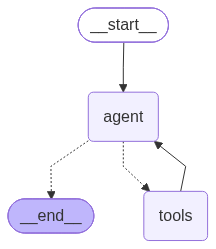

In [10]:
graph = workflow.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
messages = [
    SystemMessage(
        content="You are a helpful assistant that can call APIs to get information."
    ),
    HumanMessage(content="Get a random post from the API."),
]

In [12]:
result = graph.invoke(input={"messages": messages})

print(result)

{'messages': [SystemMessage(content='You are a helpful assistant that can call APIs to get information.', additional_kwargs={}, response_metadata={}, id='a58b9e91-3b81-42a3-a36d-0eeb27be63e4'), HumanMessage(content='Get a random post from the API.', additional_kwargs={}, response_metadata={}, id='d0759bf1-57fa-489a-809b-05c077f69ba4'), AIMessage(content=[{'arguments': '{}', 'call_id': 'call_rrv10bxT6j7yJGaKtR8M0j0d', 'name': 'get_random_post_tool', 'type': 'function_call', 'id': 'fc_012e83e6738031f9006ab6b6228d2c87d2942031931c6acee3', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_012e83e6738031f9006ab6b621327087d28097820ac291d254', 'created_at': 1790359073.0, 'metadata': {}, 'model': 'gpt-5.6-sol', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-5.6-sol'}, id='resp_012e83e6738031f9006ab6b621327087d28097820ac291d254', tool_calls=[{'name': 'get_random_post_tool', 'args': {}, 'id': 'call

In [13]:
for message in result["messages"]:
    message.pretty_print()

================================ System Message ================================

You are a helpful assistant that can call APIs to get information.
================================ Human Message =================================

Get a random post from the API.
================================== Ai Message ==================================

[{'arguments': '{}', 'call_id': 'call_rrv10bxT6j7yJGaKtR8M0j0d', 'name': 'get_random_post_tool', 'type': 'function_call', 'id': 'fc_012e83e6738031f9006ab6b6228d2c87d2942031931c6acee3', 'status': 'completed'}]
Tool Calls:
  get_random_post_tool (call_rrv10bxT6j7yJGaKtR8M0j0d)
 Call ID: call_rrv10bxT6j7yJGaKtR8M0j0d
  Args:
================================= Tool Message =================================
Name: get_random_post_tool

{"userId": 1, "id": 9, "title": "nesciunt iure omnis dolorem tempora et accusantium", "body": "consectetur animi nesciunt iure dolore\nenim quia ad\nveniam autem ut quam aut nobis\net est aut quod aut provident voluptas au

In [15]:
result["messages"][-1].content

[{'type': 'text',
  'text': '**Random Post #9**\n\n**Title:** nesciunt iure omnis dolorem tempora et accusantium\n\n**Body:**  \nconsectetur animi nesciunt iure dolore  \nenim quia ad  \nveniam autem ut quam aut nobis  \net est aut quod aut provident voluptas autem voluptas\n\n**User ID:** 1',
  'annotations': [],
  'id': 'msg_012e83e6738031f9006ab6b625284c87d2b1a6a5a2bc526f32',
  'phase': 'final_answer'}]

In [16]:
result["messages"][-1].text

'**Random Post #9**\n\n**Title:** nesciunt iure omnis dolorem tempora et accusantium\n\n**Body:**  \nconsectetur animi nesciunt iure dolore  \nenim quia ad  \nveniam autem ut quam aut nobis  \net est aut quod aut provident voluptas autem voluptas\n\n**User ID:** 1'

In [19]:
print(result["messages"][-1].text)

**Random Post #9**

**Title:** nesciunt iure omnis dolorem tempora et accusantium

**Body:**  
consectetur animi nesciunt iure dolore  
enim quia ad  
veniam autem ut quam aut nobis  
et est aut quod aut provident voluptas autem voluptas

**User ID:** 1
